In [1]:
import requests
import io
import zipfile
response = requests.get("https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip")
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
  z.extractall()
print("downloaded and extracted")

downloaded and extracted


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

df_hour = pd.read_csv("hour.csv")
training_set_hour = df_hour.sample(frac = .75, random_state = 442)
testing_set_hour = df_hour.drop(training_set_hour.index)
df_hour.fillna(0)

df_day = pd.read_csv("day.csv")
training_set_day = df_day.sample(frac = .75, random_state = 442)
testing_set_day = df_day.drop(training_set_day.index)
df_day.fillna(0)

# data preprocessing
features_hour = ['season',
  'yr',
  'mnth',
  'hr',
  'holiday',
  'weekday',
  'workingday',
  'weathersit',
  'temp',
  'atemp',
  'hum',
  'windspeed']
features_day = ['season',
 'yr',
 'mnth',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed']

columns_todrop = ['instant','dteday','casual','registered']

training_set_hour = training_set_hour.drop(columns = columns_todrop)
training_set_day = training_set_day.drop(columns = columns_todrop)

testing_set_hour = testing_set_hour.drop(columns = columns_todrop)
testing_set_day = testing_set_day.drop(columns = columns_todrop)

In [3]:
# training dataset initialization
y_train_hour = training_set_hour["cnt"]
X_train_hour = training_set_hour.drop("cnt", axis = 1)
X_train_hour = training_set_hour[features_hour]

y_train_day = training_set_day["cnt"]
X_train_day = training_set_day.drop("cnt", axis = 1)
X_train_day = training_set_day[features_day]

# testing dataset initialization

X_test_hour = testing_set_hour[features_hour]
y_test_hour = testing_set_hour["cnt"]
y_test_hour.to_numpy()

X_test_day = testing_set_day[features_day]
y_test_day = testing_set_day["cnt"]
y_test_day.to_numpy()




X_train_hour = training_set_hour[features_hour].copy()
x_test_hour = testing_set_hour[features_hour].copy()

X_train_day = training_set_day[features_day].copy()
x_test_day = testing_set_day[features_day].copy()

# Scaling the datasets
# for the hour dataset

median_hour = X_train_hour.median()
q1_hour = X_train_hour.quantile(.25)
q3_hour = X_train_hour.quantile(.75)
iqr_hour = q3_hour - q1_hour

iqr_hour = iqr_hour.replace(0,1)

X_train_hour_scaled = (X_train_hour - median_hour) / iqr_hour
X_test_hour_scaled = (x_test_hour - median_hour) / iqr_hour

# for the day dataset

median_day = X_train_day.median()
q1_day = X_train_day.quantile(.25)
q3_day = X_train_day.quantile(.75)
iqr_day = q3_day - q1_day

iqr_day = iqr_day.replace(0,1)

X_train_day_scaled = (X_train_day - median_day) / iqr_day
X_test_day_scaled = (x_test_day - median_day) / iqr_day


X_hour = X_train_hour_scaled.to_numpy()
X_day = X_train_day_scaled.to_numpy()


X_test_hour = X_test_hour_scaled.to_numpy()
X_test_day = X_test_day_scaled.to_numpy()

y_hour = np.array(y_train_hour).ravel()
y_day = np.array(y_train_day).ravel()


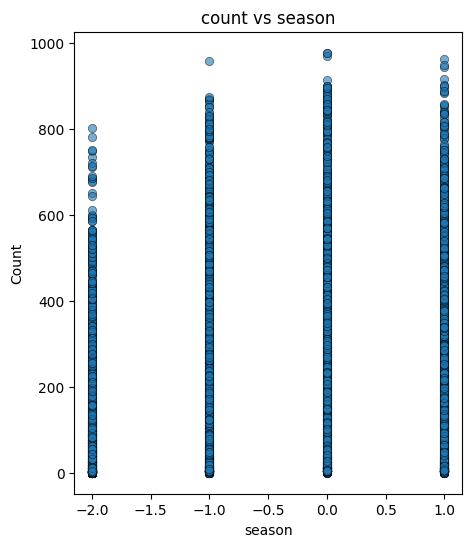

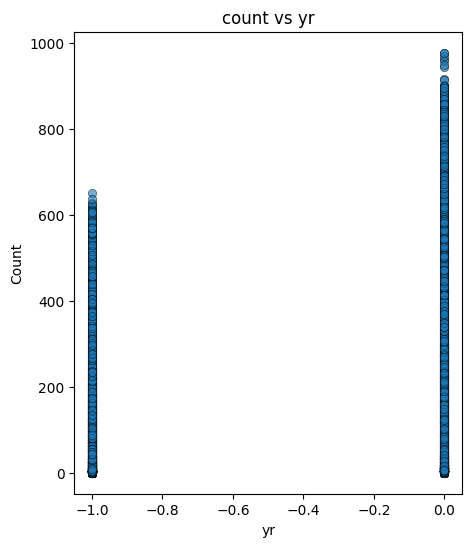

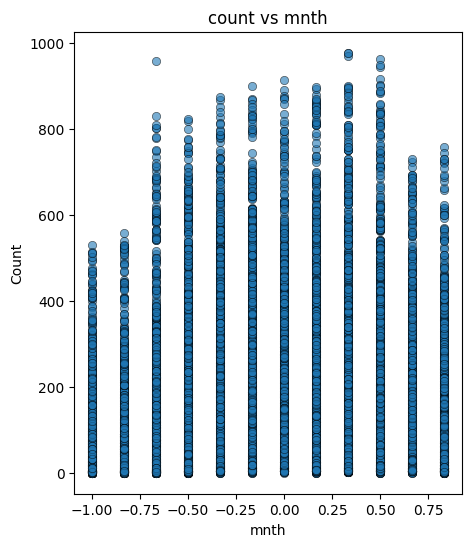

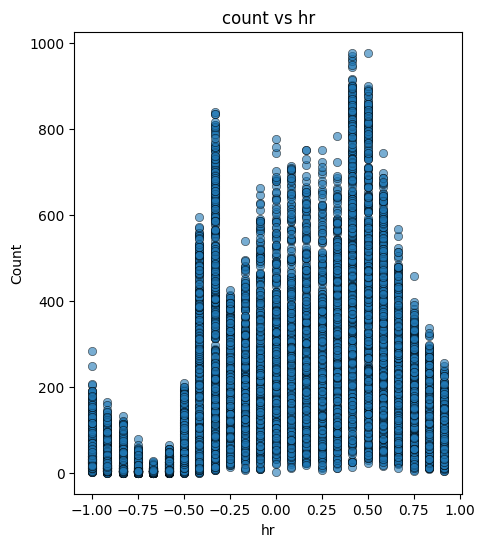

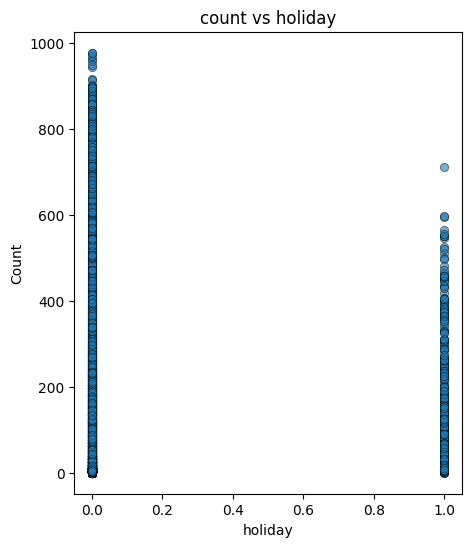

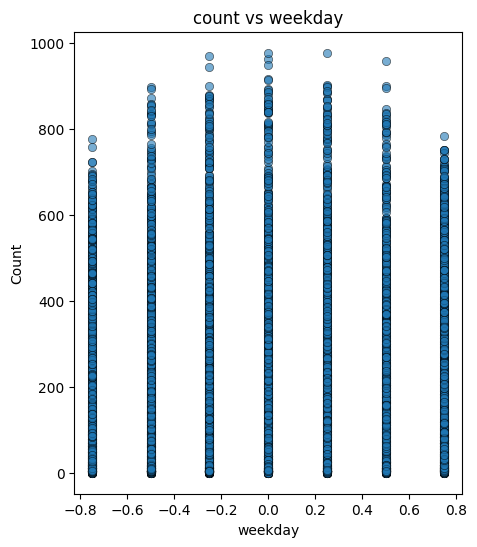

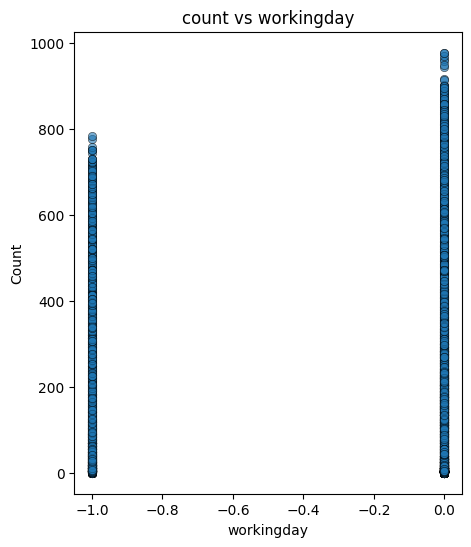

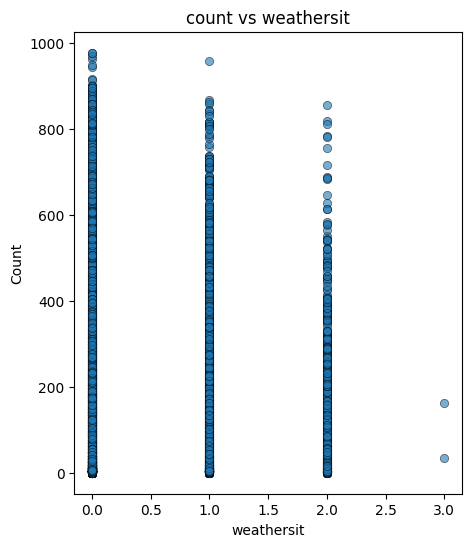

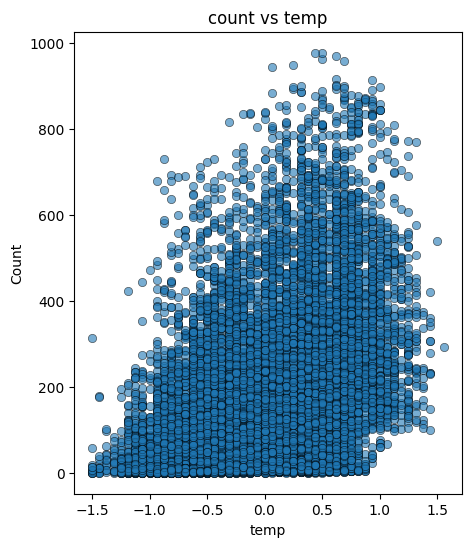

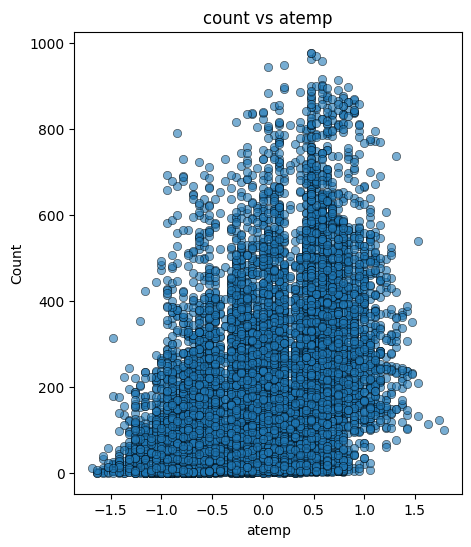

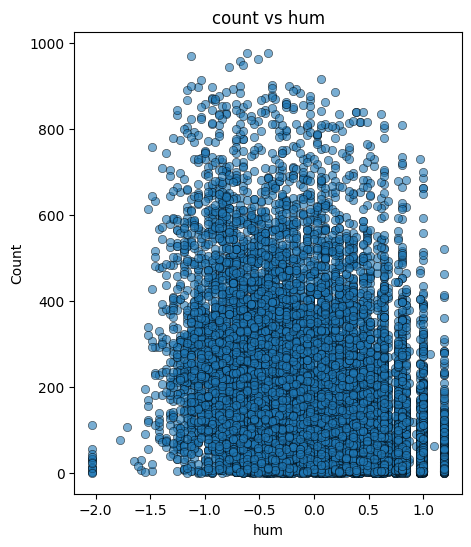

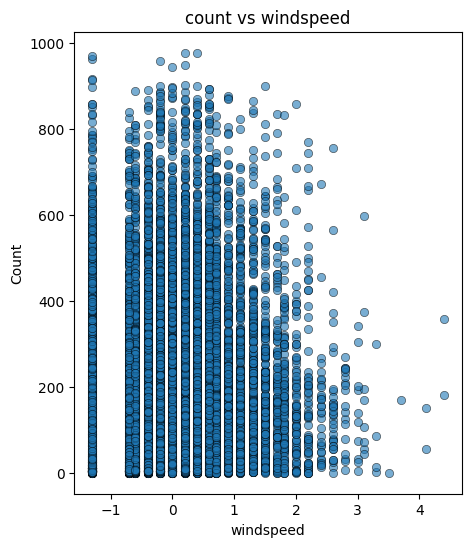

In [4]:
feature_names_hour = X_train_hour_scaled.columns
feature_names_day = X_train_day_scaled.columns


# no of counts visualization with respect to all the features of scaled features of X_hour
for i in range(X_hour.shape[1]):
  fig, ax = plt.subplots(figsize = (5,6))

  ax.scatter(
      X_hour[:, i],
      y_hour,
      marker = "o",
      edgecolors = "black",
      linewidths = .5,
      alpha = .6
  )

  ax.set_title(f"count vs {feature_names_hour[i]}")
  ax.set_xlabel(feature_names_hour[i])
  ax.set_ylabel("Count")

  plt.show()


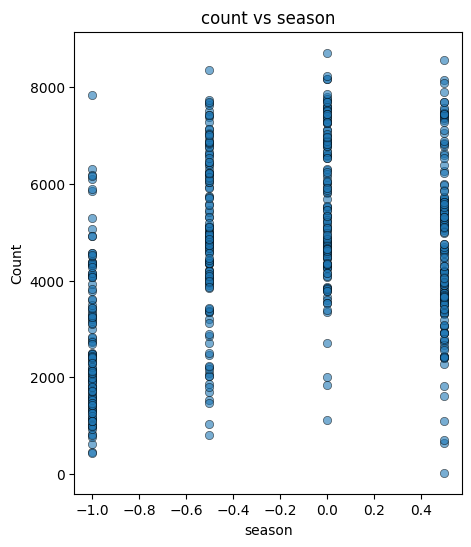

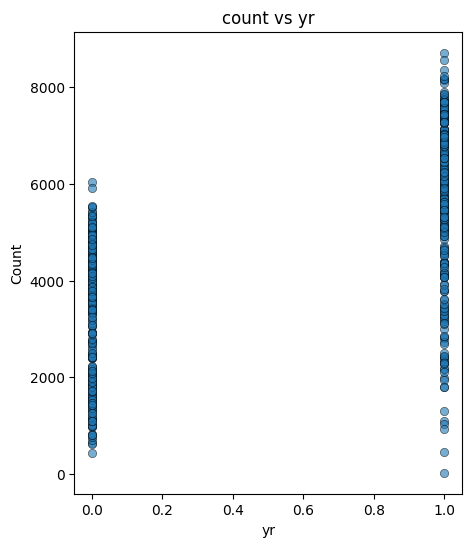

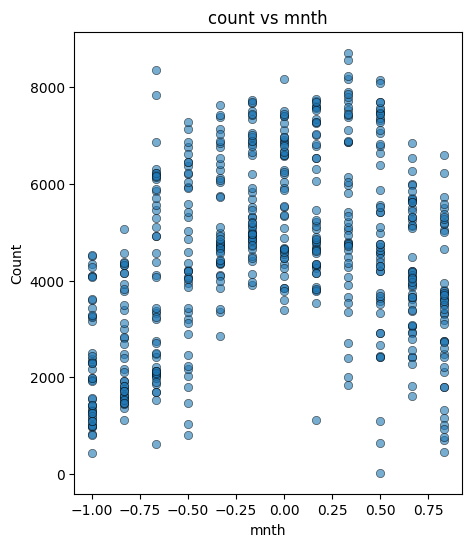

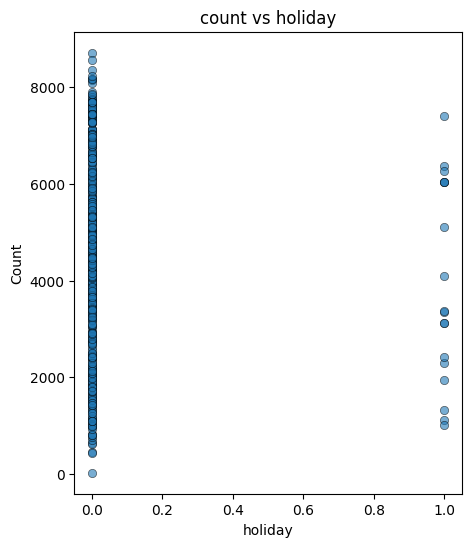

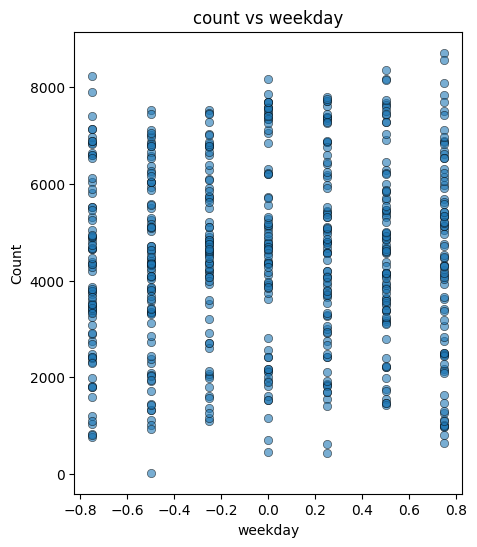

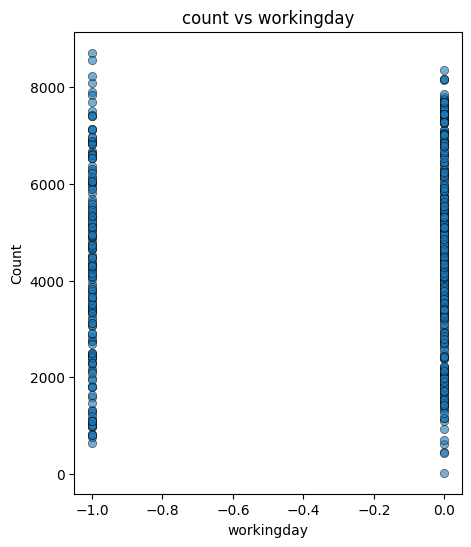

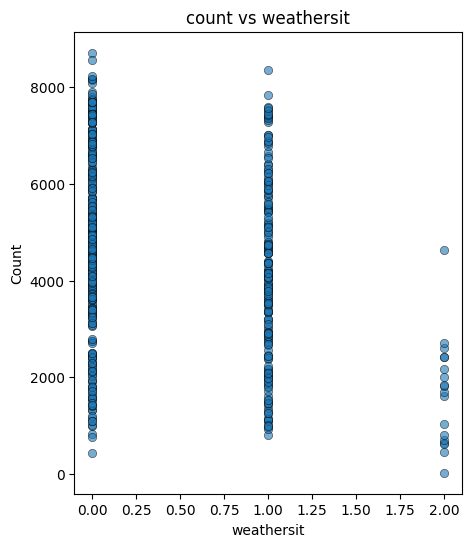

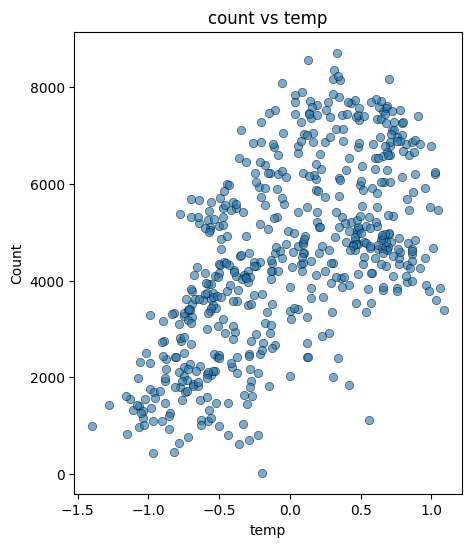

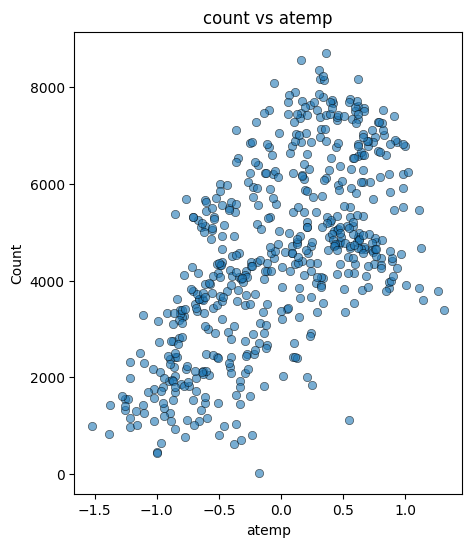

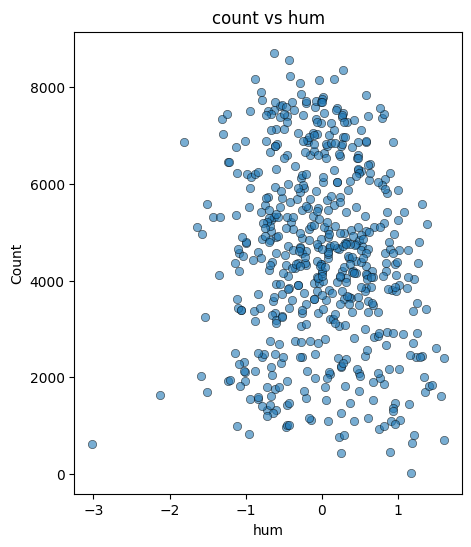

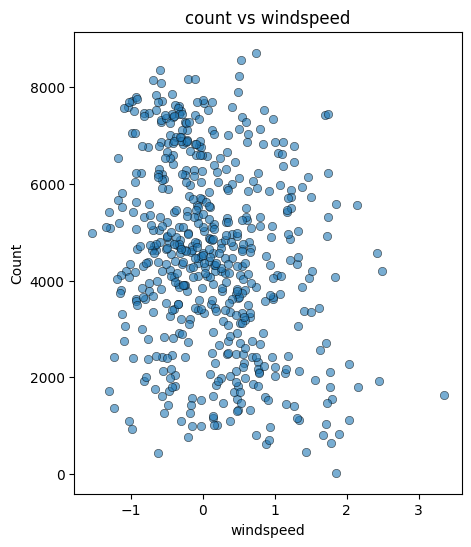

In [5]:
# no of counts visualization with respect to all the scaled features of X_hour
for i in range(X_day.shape[1]):
  fig, ax = plt.subplots(figsize = (5,6))

  ax.scatter(
      X_day[:, i],
      y_day,
      marker = "o",
      edgecolors = "black",
      linewidths = .5,
      alpha = .6
  )

  ax.set_title(f"count vs {feature_names_day[i]}")
  ax.set_xlabel(feature_names_day[i])
  ax.set_ylabel("Count")

  plt.show()

In [6]:
# cost computation

def compute_cost(X, y, w, b, lbd):
  cost = 0.0
  reg = 0.0
  m,n = X.shape
  for i in range(m):
    f_wb = np.dot(X[i], w) + b
    cost += (f_wb - y[i]) ** 2

  for i in range(n):
    reg += w[i] ** 2
  reg_term = (lbd / (2 * m)) * reg

  return cost / (2 * m) + reg_term

# computing gradient

def compute_gradient(X, y, w, b, lbd):
  m,n = X.shape

  dj_dw = np.zeros(n)
  dj_db = 0.0

  for i in range(m):
    f_wb = np.dot(X[i], w) + b
    error = (f_wb - y[i])

    dj_db += error

    for j in range(n):
      dj_dw[j] += error * X[i, j]

  for j in range(n):
    dj_dw[j] += (lbd / m) * w[j]

  dj_dw = dj_dw / m
  dj_db = dj_db / m

  return dj_dw, dj_db


In [7]:
# Gradient Descent

def gradient_descent(X_train, y_train, compute_cost, compute_gradient, l_rate, iter, w_i, b_i, lbd):

  J_hist = []
  param_hist = []
  iteration = []
  w = w_i
  b = b_i

  for i in range(iter):
    dj_dw, dj_db = compute_gradient(X_train, y_train, w, b, lbd)

    w = w - (dj_dw * l_rate)
    b = b - (dj_db * l_rate)


    if i % math.ceil(iter / 10) == 0:
      iteration.append(i)
      J_hist.append(compute_cost(X_train, y_train, w, b, lbd))
      param_hist.append([w, b])
      print(f"Iteration: {i} and Cost: {J_hist[-1]}")
  return w, b, J_hist, param_hist, iteration


In [8]:
def viewCost(J_hist, iteration, param_hist):
  plt.plot(iteration, J_hist)
  plt.title("Cost function over iterations")
  plt.xlabel("Iteration")
  plt.ylabel("Cost J")
  plt.show()

In [9]:
w_i_hour = np.zeros((X_train_hour.shape[1]))
b_i_hour = 0.0
w_hour, b_hour, J_hist_hour, param_hist_hour, iteration_hour = gradient_descent(X_hour, y_hour, compute_cost, compute_gradient, 0.01, 5000, w_i_hour, b_i_hour, .001)

Iteration: 0 and Cost: 33979.05690169119
Iteration: 500 and Cost: 10878.05535440733
Iteration: 1000 and Cost: 10314.405956044315
Iteration: 1500 and Cost: 10191.904354919396
Iteration: 2000 and Cost: 10158.467581550547
Iteration: 2500 and Cost: 10147.815402811857
Iteration: 3000 and Cost: 10143.882026354786
Iteration: 3500 and Cost: 10142.181103634473
Iteration: 4000 and Cost: 10141.315203687267
Iteration: 4500 and Cost: 10140.802692624713


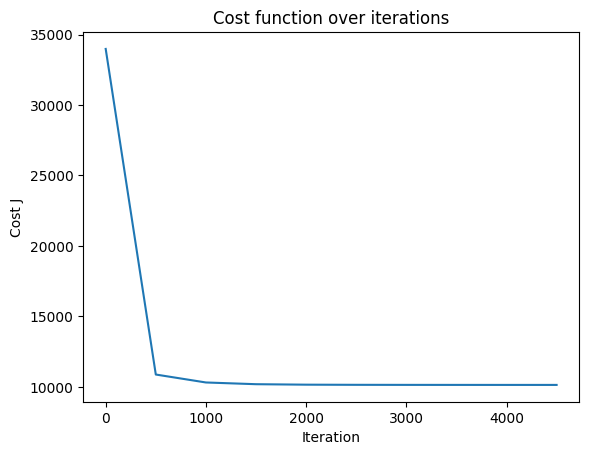

In [10]:
# print(J_hist_hour)
viewCost(J_hist_hour, iteration_hour, param_hist_hour)

In [11]:
w_i_day = np.zeros((X_train_day.shape[1]))
b_i_day = 0.0
w_day, b_day, J_hist_day, param_hist_day, iteration_day = gradient_descent(X_day, y_day, compute_cost, compute_gradient, 0.001, 5000, w_i_day, b_i_day, .001)

Iteration: 0 and Cost: 11980432.37433967
Iteration: 500 and Cost: 3551930.0685492973
Iteration: 1000 and Cost: 1573862.8849351371
Iteration: 1500 and Cost: 983730.2992084688
Iteration: 2000 and Cost: 751816.6065425602
Iteration: 2500 and Cost: 638384.5136206532
Iteration: 3000 and Cost: 574381.5675032784
Iteration: 3500 and Cost: 534581.4801508815
Iteration: 4000 and Cost: 507879.82033975073
Iteration: 4500 and Cost: 488782.0810486712


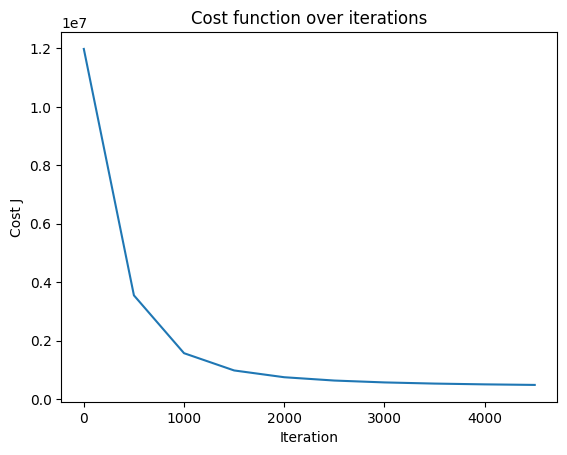

In [12]:
viewCost(J_hist_day, iteration_day, param_hist_day)

In [13]:
def predict(X, w, b):
  return np.dot(X, w) + b

[-74.26987054 -69.88057245 -62.24207577 ... 193.47451999 189.34937134
 198.32097254]


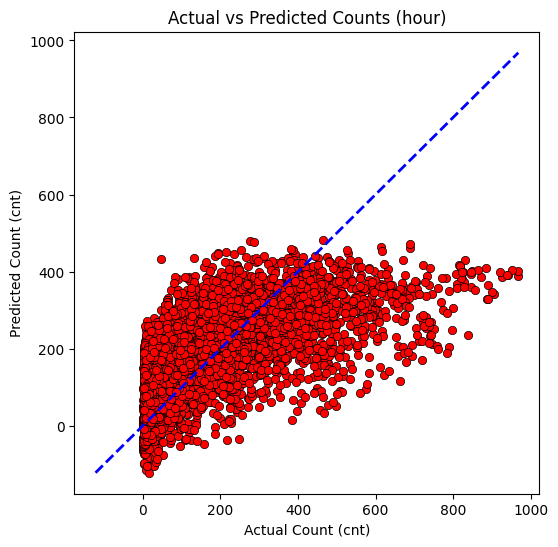

In [14]:
y_pred_hour = predict(X_test_hour, w_hour, b_hour)
print(y_pred_hour)

plt.figure(figsize=(6,6))

plt.scatter(
    y_test_hour,
    y_pred_hour,
    color='red',
    edgecolors='black',
    linewidths=0.5
)


min_val = min(y_test_hour.min(), y_pred_hour.min())
max_val = max(y_test_hour.max(), y_pred_hour.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'b--',
    linewidth=2
)

plt.title("Actual vs Predicted Counts (hour)")
plt.xlabel("Actual Count (cnt)")
plt.ylabel("Predicted Count (cnt)")


plt.show()

[1038.52253049 1585.23863536 1724.52704235 1507.71557071  615.04815398
 1195.47911258  762.88712071  106.16675766  963.99494055  841.88820165
 1077.49095814 1087.90849745 2051.48306469  570.68375926 1737.73760311
 3047.16092422  921.41978844 2226.35005453 1526.11559188 1557.5611425
  960.03033198  876.8998216  1689.82499796 3210.10822966 1388.64403005
 2128.44587139 2400.69843402 2419.20679891 2952.03147935 3154.62256198
 2539.7947583  2897.11627365 3434.50129082 2959.12918212 1813.89673893
 2958.29108928 3039.9926565  1858.08093979 3602.99870988 2752.33471369
 3230.11450296 3244.98362831 4443.64712704 3732.43335629 3159.66266214
 3620.04050066 5118.50352759 4352.35098526 4963.87971001 3802.60697408
 3705.09743904 4036.80679463 4593.34430637 5911.69534378 5050.82117441
 4277.40785047 4669.0680671  5069.72455633 6484.06821879 4985.09257925
 5218.12222758 5737.83243489 4930.39706353 4443.52403251 5228.98777631
 4480.65449453 4790.50981079 3681.49275829 3777.92349221 3722.17913944
 3371.9

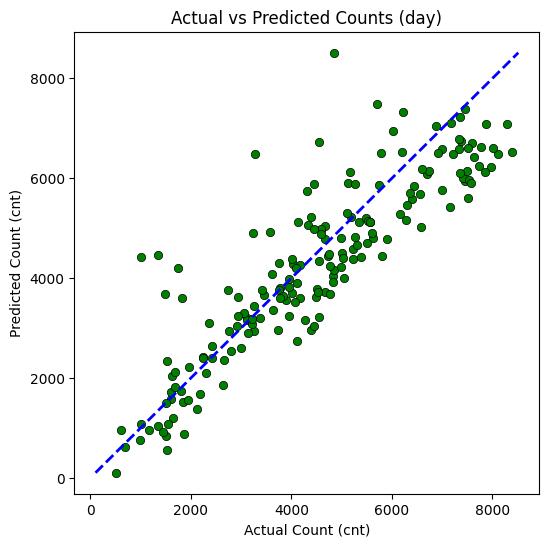

In [15]:
y_pred_day = predict(X_test_day, w_day, b_day)
print(y_pred_day)

plt.figure(figsize=(6,6))

plt.scatter(
    y_test_day,
    y_pred_day,
    color='green',
    edgecolors='black',
    linewidths=0.5
)


min_val = min(y_test_day.min(), y_pred_day.min())
max_val = max(y_test_day.max(), y_pred_day.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'b--',
    linewidth=2
)

plt.title("Actual vs Predicted Counts (day)")
plt.xlabel("Actual Count (cnt)")
plt.ylabel("Predicted Count (cnt)")


plt.show()

In [16]:
# coefficient of determination
def r2_calc(y_test, y_pred):
  ss_res = np.sum((y_test - y_pred)**2)
  ss_tot = np.sum((y_test - np.mean(y_test))**2)

  r2 = 1 - (ss_res/ss_tot)

  return r2

In [17]:
print("R² for hour =", r2_calc(y_test_hour, y_pred_hour))
print("R² for day =", r2_calc(y_test_day, y_pred_day))

R² for hour = 0.39592636248099977
R² for day = 0.7598029992408966


In [18]:
# mean square error
def mse(X, y, y_test, y_pred, w, b, ):
  train_pred = predict(X, w, b)

  train_mse = np.mean((y - train_pred)**2)
  test_mse = np.mean((y_test - y_pred)**2)

  return float(train_mse), float(test_mse)


In [19]:
print(f"Train MSE and test mse (for hour) respectively: {mse(X_hour, y_hour, y_test_hour, y_pred_hour, w_hour, b_hour)}")
print(f"Train MSE and test mse (for day) respectively: {mse(X_day, y_day, y_test_day, y_pred_day, w_day, b_day)}")

Train MSE and test mse (for hour) respectively: (20280.91956946033, 19601.402341536304)
Train MSE and test mse (for day) respectively: (948770.0435424481, 959449.954447267)


## Performing gradient descent by squaring the features

In [20]:
# for hour
for feature in features_hour:
    X_train_hour[feature + "_sq"] = X_train_hour[feature] ** 2
    x_test_hour[feature + "_sq"] = x_test_hour[feature] ** 2


# Normalize after squaring
X_scaled_hour = (X_train_hour - X_train_hour.mean(axis=0)) / X_train_hour.std(axis=0)
X_test_scaled_hour = (x_test_hour - x_test_hour.mean(axis=0)) / x_test_hour.std(axis=0)

# for day
for feature in features_day:
    X_train_day[feature + "_sq"] = X_train_day[feature] ** 2
    x_test_day[feature + "_sq"] = x_test_day[feature] ** 2


# Normalize after squaring
X_scaled_day = (X_train_day - X_train_day.mean(axis=0)) / X_train_day.std(axis=0)
X_test_scaled_day = (x_test_day - x_test_day.mean(axis=0)) / x_test_day.std(axis=0)


In [21]:
# hour
w_i_hour = np.zeros((X_scaled_hour.shape[1],))
b_i_hour = 0.0

# Convert to numpy arrays on the fly to bypass Pandas indexing
X_numpy_hour = X_scaled_hour.to_numpy() if hasattr(X_scaled_hour, 'to_numpy') else np.asarray(X_scaled_hour)
y_numpy_hour = y_hour.to_numpy().flatten() if hasattr(y_hour, 'to_numpy') else np.asarray(y_hour).flatten()

# Run gradient descent safely
w_hour, b_hour, J_hist_hour, param_hist_hour, iteration_hour = gradient_descent(
    X_numpy_hour, y_numpy_hour, compute_cost, compute_gradient, 0.01, 5000, w_i_hour, b_i_hour, 20
)

Iteration: 0 and Cost: 33767.198312336135
Iteration: 500 and Cost: 9970.210918576615
Iteration: 1000 and Cost: 9556.73194622905
Iteration: 1500 and Cost: 9257.314749712466
Iteration: 2000 and Cost: 9039.762788749817
Iteration: 2500 and Cost: 8881.793757872445
Iteration: 3000 and Cost: 8767.25232125429
Iteration: 3500 and Cost: 8684.374635580692
Iteration: 4000 and Cost: 8624.575612275932
Iteration: 4500 and Cost: 8581.582628158578


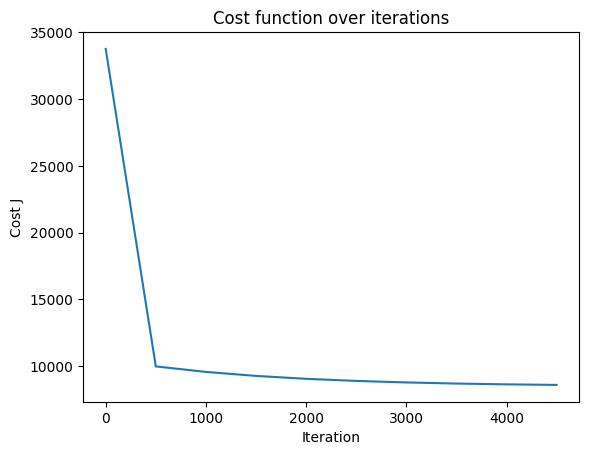

In [22]:
# print(J_hist_hour)
viewCost(J_hist_hour, iteration_hour, param_hist_hour)
# print(w.shape)
# print(J_hist.size())

In [23]:
# day
w_i_day = np.zeros((X_scaled_day.shape[1],))
b_i_day = 0.0

# Convert to numpy arrays on the fly to bypass Pandas indexing
X_numpy_day = X_scaled_day.to_numpy() if hasattr(X_scaled_day, 'to_numpy') else np.asarray(X_scaled_day)
y_numpy_day = y_day.to_numpy().flatten() if hasattr(y_day, 'to_numpy') else np.asarray(y_day).flatten()

# Run gradient descent safely
w_day, b_day, J_hist_day, param_hist_day, iteration_day = gradient_descent(
    X_numpy_day, y_numpy_day, compute_cost, compute_gradient, 0.001, 2000, w_i_day, b_i_day, 20
)

Iteration: 0 and Cost: 11983440.506757813
Iteration: 200 and Cost: 7617002.298680172
Iteration: 400 and Cost: 5116793.18192937
Iteration: 600 and Cost: 3532305.425080501
Iteration: 800 and Cost: 2493597.6173232077
Iteration: 1000 and Cost: 1804309.7921744061
Iteration: 1200 and Cost: 1344440.5427874539
Iteration: 1400 and Cost: 1036706.2297905106
Iteration: 1600 and Cost: 830327.0507673528
Iteration: 1800 and Cost: 691644.8974640338


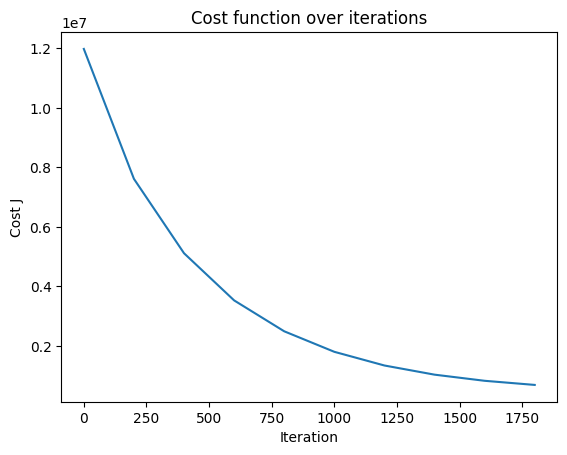

In [24]:
# print(J_hist_day)
viewCost(J_hist_day, iteration_day, param_hist_day)
# print(w.shape)
# print(J_hist.size())

Actual test shape: (4345,)
Predicted shape:   (4345,)


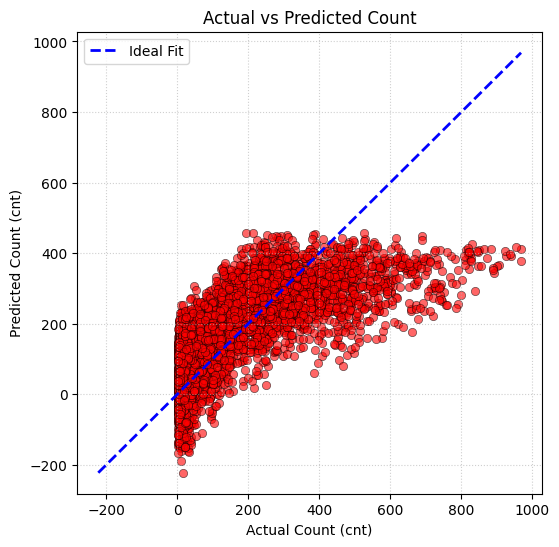

In [25]:
# Predicting count vs actual count using squared features
X_test_numpy_hour = X_test_scaled_hour.to_numpy() if hasattr(X_test_scaled_hour, 'to_numpy') else np.asarray(X_test_scaled_hour)
y_test_numpy_hour = y_test_hour.to_numpy().flatten() if hasattr(y_test_hour, 'to_numpy') else np.asarray(y_test_hour).flatten()

y_pred_hour = predict(X_test_numpy_hour, w_hour, b_hour).flatten()

print("Actual test shape:", y_test_numpy_hour.shape)
print("Predicted shape:  ", y_pred_hour.shape)

# 4. Plotting
plt.figure(figsize=(6,6))

plt.scatter(
    y_test_numpy_hour,
    y_pred_hour,
    color='red',
    edgecolors='black',
    linewidths=0.5,
    alpha=0.6
)

# Reference line limits
min_val = min(y_test_numpy_hour.min(), y_pred_hour.min())
max_val = max(y_test_numpy_hour.max(), y_pred_hour.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'b--',
    linewidth=2,
    label='Ideal Fit'
)

plt.title("Actual vs Predicted Count")
plt.xlabel("Actual Count (cnt)")
plt.ylabel("Predicted Count (cnt)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.show()

Actual test shape: (183,)
Predicted shape:   (183,)


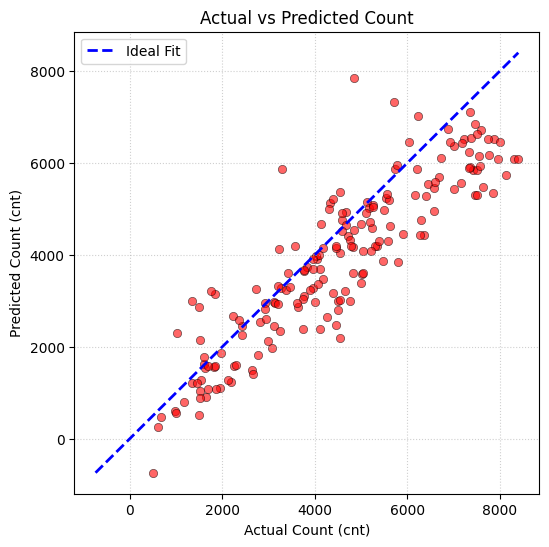

In [26]:
# Predicting count vs actual count using squared features
X_test_numpy_day = X_test_scaled_day.to_numpy() if hasattr(X_test_scaled_day, 'to_numpy') else np.asarray(X_test_scaled_day)
y_test_numpy_day = y_test_day.to_numpy().flatten() if hasattr(y_test_day, 'to_numpy') else np.asarray(y_test_day).flatten()

y_pred_day = predict(X_test_numpy_day, w_day, b_day).flatten()

print("Actual test shape:", y_test_numpy_day.shape)
print("Predicted shape:  ", y_pred_day.shape)

# 4. Plotting
plt.figure(figsize=(6,6))

plt.scatter(
    y_test_numpy_day,
    y_pred_day,
    color='red',
    edgecolors='black',
    linewidths=0.5,
    alpha=0.6
)

# Reference line limits
min_val = min(y_test_numpy_day.min(), y_pred_day.min())
max_val = max(y_test_numpy_day.max(), y_pred_day.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'b--',
    linewidth=2,
    label='Ideal Fit'
)

plt.title("Actual vs Predicted Count")
plt.xlabel("Actual Count (cnt)")
plt.ylabel("Predicted Count (cnt)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.show()

In [27]:
print("R² for hour using squared features=", r2_calc(y_test_hour, y_pred_hour))
print("R² for day using squared features=", r2_calc(y_test_day, y_pred_day))

R² for hour using squared features= 0.4856600970095787
R² for day using squared features= 0.7173079415155723


In [28]:
print(f"Train MSE and test mse (for hour) respectively using squared features: {mse(X_numpy_hour, y_numpy_hour, y_test_numpy_hour, y_pred_hour, w_hour, b_hour)}")
print(f"Train MSE and test mse (for day) respectively using squared features: {mse(X_numpy_day, y_numpy_day, y_test_numpy_day, y_pred_day, w_day, b_day)}")

Train MSE and test mse (for hour) respectively using squared features: (16963.4631367794, 16689.659592213033)
Train MSE and test mse (for day) respectively using squared features: (1162242.990743863, 1129193.4611103118)
